# Part 4.D — Hyperparameter selection

Stage D asks for the **whole** regularisation curve, not just the winning `C`:

* sweep a logarithmic grid `C ∈ {0.1, 1, 10, 100, 1000}`;
* plot training and validation AP to diagnose overfitting;
* select `C` on internal validation, then evaluate the chosen configuration
  **once** on the `*_val` test split;
* show how the bias–variance trade-off changes when only a few positives exist.

Representation: **DINOv2 ViT-S/14, 384-D CLS token** (the Stage B/C choice),
L2-normalised, same `LinearSVC` (`hinge`, `dual=True`) as Part 1.

Protocol is unchanged: the shared internal validation file names
(`results/part4_internal_val_names.csv`) select `C`; positives are the target
category and negatives are `background`; the test split is never used for
selection.

In [1]:
import json
import os
import sys
import time
from pathlib import Path


def _find_code_dir():
    '''Locate the directory containing src/ (works from code/ or the repo root).'''
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        for candidate in (base, base / "code"):
            if (candidate / "src" / "deep_models.py").exists():
                return candidate
    raise FileNotFoundError(
        "Could not find src/deep_models.py. Open the notebook from code/ or the repo root."
    )


CODE_DIR = _find_code_dir()
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))
os.chdir(CODE_DIR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score

from src.deep_eval import (
    BACKGROUND,
    CATEGORIES,
    DEFAULT_C_GRID,
    binary_subset,
    l2norm,
    save_results,
    sweep_c,
    train_svm_checked,
)
from src.deep_features import load_feature_cache

# --------------------------- experiment configuration -----------------------
CATEGORY = "motorbike"                    # highlighted in the few-shot plots
REPRESENTATION = "dinov2_vits14"
FEATURE_TAG = "dinov2_vits14"
FEATURE_KEY = "features_cls"
FEATURE_DIM = 384

C_GRID = DEFAULT_C_GRID                    # 0.1, 1, 10, 100, 1000
MAX_ITER = 20000                          # C=1000 needs more than the Stage A/B budget
SEED = 0
SHOTS_FEW = (1, 5, 10, 20)
SEEDS = (0, 1, 2)
VAL_FRACTION = 0.2

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 110
np.random.seed(SEED)

print("Representation:", REPRESENTATION, f"({FEATURE_DIM}-D)")
print("C grid:", C_GRID, "| max_iter:", MAX_ITER)

Representation: dinov2_vits14 (384-D)
C grid: (0.1, 1.0, 10.0, 100.0, 1000.0) | max_iter: 20000


## D.1 — Load the frozen features and the shared split

The DINOv2 cache is produced by Stage B (`4_dinov2.ipynb`). If it is missing,
run that notebook first; this notebook deliberately does not silently switch to
a different representation.

In [2]:
train_features, train_names, train_categories = load_feature_cache(
    FEATURE_TAG, "train", FEATURE_KEY)
test_features, test_names, test_categories = load_feature_cache(
    FEATURE_TAG, "val", FEATURE_KEY)

assert train_features.shape[1] == FEATURE_DIM
assert len(train_names) == len(train_categories)
print("Train:", train_features.shape, "| Test:", test_features.shape)

val_path = RESULTS_DIR / "part4_internal_val_names.csv"
if not val_path.exists():
    raise FileNotFoundError(
        f"{val_path} is missing. Run `3_frozen_cnn.ipynb` or `4_dinov2.ipynb` "
        "once to persist the shared internal-validation split."
    )
val_names = pd.read_csv(val_path, dtype={"file_name": str})["file_name"].to_numpy()
is_val = np.isin(train_names, val_names)
assert is_val.any(), "the shared split does not match the feature cache"
assert not np.isin(test_names, val_names).any(), "internal-val and test overlap"
print(f"train={int((~is_val).sum())}  internal-val={int(is_val.sum())}  "
      f"test={len(test_names)}")

train_l2, test_l2 = l2norm(train_features), l2norm(test_features)

Train: (2791, 384) | Test: (2796, 384)
train=2126  internal-val=665  test=2796


## D.2 — Many-shot sweep: training vs validation AP

For each category the classifier is fitted five times on the training rows
(internal-validation rows held out), then refitted once at the selected `C` on
**all** training rows and scored once on test. The selected point is marked on
the curve.

In [3]:
test_sets = {cat: binary_subset(cat, test_l2, test_names, test_categories)
             for cat in CATEGORIES}

many_rows, many_selected = [], []
t0 = time.perf_counter()

for cat in CATEGORIES:
    X_tr, y_tr, n_tr = binary_subset(cat, train_l2, train_names, train_categories)
    val_mask = np.isin(n_tr, val_names)
    X_te, y_te, _ = test_sets[cat]

    sweep = sweep_c(X_tr, y_tr, val_mask, C_GRID, max_iter=MAX_ITER, seed=SEED)
    best_C = float(sweep.loc[sweep["val_ap"].idxmax(), "C"])
    W, b, fit_s, conv, n_iter = train_svm_checked(
        X_tr, y_tr, best_C, max_iter=MAX_ITER, seed=SEED)
    test_ap = float(average_precision_score(y_te, X_te @ W + b))

    sweep = sweep.assign(category=cat, selected=False)
    sweep.loc[sweep["C"] == best_C, "selected"] = True
    many_rows.append(sweep)
    many_selected.append(dict(
        category=cat, C=best_C, val_ap=float(sweep.loc[sweep.selected, "val_ap"].iloc[0]),
        train_ap=float(sweep.loc[sweep.selected, "train_ap"].iloc[0]),
        test_ap=test_ap, fit_s=float(fit_s), converged=bool(conv), n_iter=int(n_iter),
    ))
    flag = "" if conv else "  [not converged]"
    print(f"{cat:<10s} C={best_C:<6g} train AP={sweep.loc[sweep.selected, 'train_ap'].iloc[0]:.4f}  "
          f"val AP={sweep.loc[sweep.selected, 'val_ap'].iloc[0]:.4f}  test AP={test_ap:.4f}{flag}")

many = pd.concat(many_rows, ignore_index=True)
many_sel = pd.DataFrame(many_selected)
save_results(many, RESULTS_DIR / "part4d_many_shot_sweep.csv")
save_results(many_sel, RESULTS_DIR / "part4d_selected_c.csv")
print(f"\n{time.perf_counter() - t0:.0f}s")
display(many_sel.round(4))

aeroplane  C=0.1    train AP=0.9991  val AP=1.0000  test AP=1.0000
car        C=1      train AP=0.9839  val AP=0.9768  test AP=0.9749
horse      C=0.1    train AP=0.9918  val AP=1.0000  test AP=0.9980
motorbike  C=10     train AP=1.0000  val AP=0.9873  test AP=0.9818
person     C=1      train AP=0.9918  val AP=0.9865  test AP=0.9820

2s


,category,C,val_ap,train_ap,test_ap,fit_s,converged,n_iter
0,aeroplane,0.1,1.0000,0.9991,1.0000,0.0103,True,33
1,car,1.0,0.9768,0.9839,0.9749,0.0247,True,95
2,horse,0.1,1.0000,0.9918,0.9980,0.0111,True,44
3,motorbike,10.0,0.9873,1.0000,0.9818,0.0190,True,132
4,person,1.0,0.9865,0.9918,0.9820,0.0399,True,122


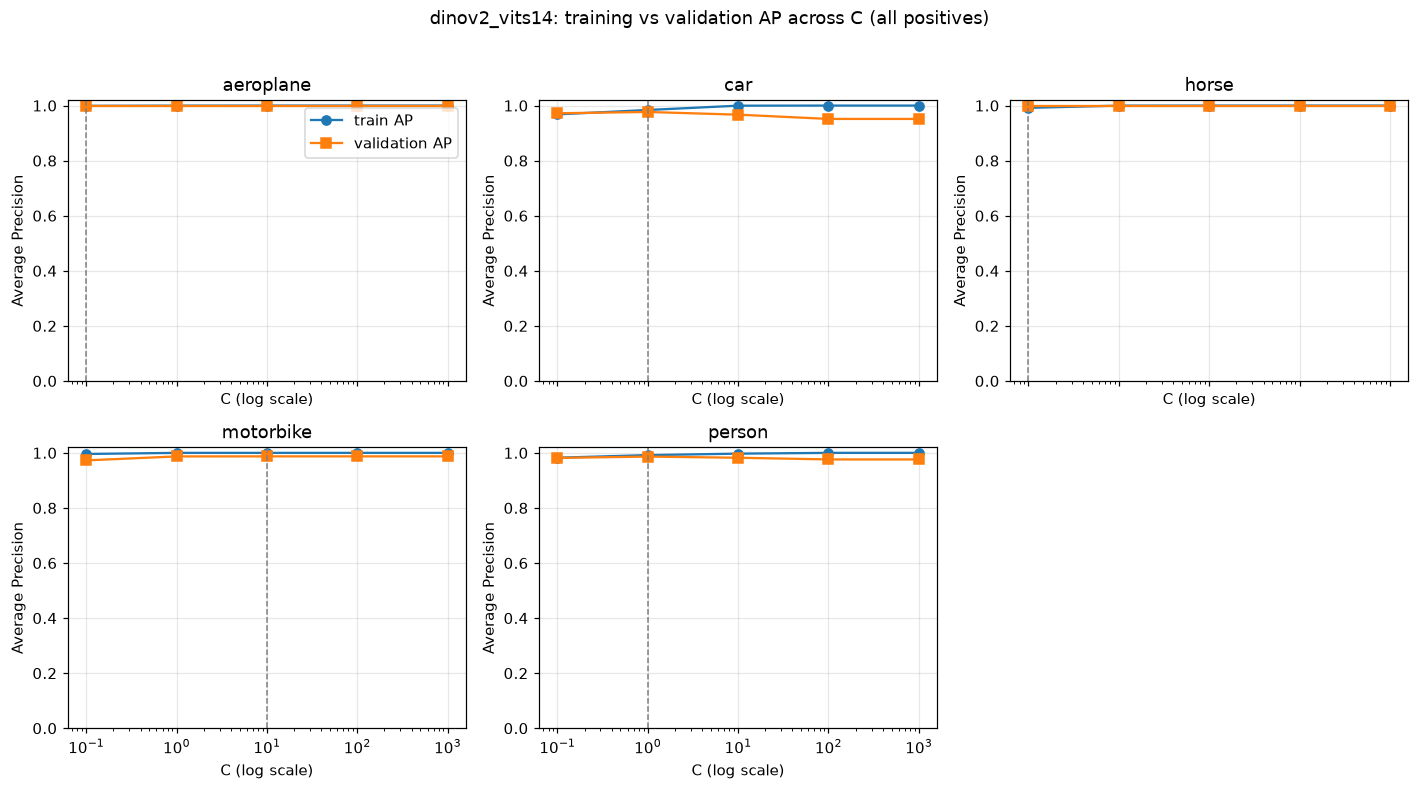

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for ax, cat in zip(axes.ravel(), CATEGORIES):
    g = many[many.category == cat]
    ax.plot(g.C, g.train_ap, marker="o", label="train AP")
    ax.plot(g.C, g.val_ap, marker="s", label="validation AP")
    chosen = g.loc[g.selected]
    ax.axvline(float(chosen.C.iloc[0]), color="grey", ls="--", lw=1)
    ax.set_xscale("log")
    ax.set_title(cat)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.3)
    ax.set_xlabel("C (log scale)")
    ax.set_ylabel("Average Precision")
axes.ravel()[-1].axis("off")
axes[0, 0].legend()
fig.suptitle(f"{REPRESENTATION}: training vs validation AP across C (all positives)", y=1.02)
plt.tight_layout()
plt.show()

**Reading the plot.** Training AP rises monotonically with `C`. Validation AP
follows it while the margin is still regularised, then plateaus or drops: that
is the variance side of the trade-off. The dashed line is the value selected on
internal validation, not the test-optimal value.

## D.3 — One `C` for all classes, or per-class `C`?

A per-class `C` is the protocol used in Stages A/B. A single global `C` (chosen
by mean validation AP across classes) is cheaper and easier to deploy. Both are
evaluated on test to show whether the extra tuning is worth it.

In [5]:
pivot = many.pivot_table(index="C", columns="category", values="val_ap")
mean_val = pivot.mean(axis=1)
global_C = float(mean_val.idxmax())
print(f"Global C selected by mean validation AP: {global_C:g}")

global_rows = []
for cat in CATEGORIES:
    X_tr, y_tr, _ = binary_subset(cat, train_l2, train_names, train_categories)
    X_te, y_te, _ = test_sets[cat]
    W, b, fit_s, conv, n_iter = train_svm_checked(
        X_tr, y_tr, global_C, max_iter=MAX_ITER, seed=SEED)
    global_rows.append(dict(
        category=cat, C=global_C,
        val_ap=float(pivot.loc[global_C, cat]),
        test_ap=float(average_precision_score(y_te, X_te @ W + b)),
        fit_s=float(fit_s), converged=bool(conv),
    ))

global_df = pd.DataFrame(global_rows)
comparison = pd.DataFrame([
    dict(selection="per-class C", C="varies", test_mAP=float(many_sel.test_ap.mean())),
    dict(selection="global C", C=global_C, test_mAP=float(global_df.test_ap.mean())),
])
display(comparison.round(4))
display(global_df.round(4).reset_index(drop=True))
save_results(comparison, RESULTS_DIR / "part4d_global_vs_per_class.csv")

Global C selected by mean validation AP: 1


,selection,C,test_mAP
0,per-class C,varies,0.9873
1,global C,1.0,0.9866


,category,C,val_ap,test_ap,fit_s,converged
0,aeroplane,1.0,1.0000,1.0000,0.0161,True
1,car,1.0,0.9768,0.9749,0.0219,True
2,horse,1.0,1.0000,0.9944,0.0126,True
3,motorbike,1.0,0.9871,0.9820,0.0114,True
4,person,1.0,0.9865,0.9820,0.0334,True


WindowsPath('results/part4d_global_vs_per_class.csv')

## D.4 — Few-shot sweeps: does the optimal `C` move?

The same five-point sweep is repeated for `1, 5, 10, 20` positives (3 sampling
seeds, fixed full background training set). `C` is selected by the **mean**
validation AP across seeds, then each seed is refitted and scored on test once.

In [6]:
def category_pools(cat):
    pos = np.flatnonzero(train_categories == cat)
    neg = np.flatnonzero(train_categories == BACKGROUND)
    return pos[~is_val[pos]], neg[~is_val[neg]], pos[is_val[pos]], neg[is_val[neg]]


def build_training(cat, n_pos, seed):
    '''Return training matrix, labels, internal-val matrix/labels.'''
    pos_tr, neg_tr, pos_va, neg_va = category_pools(cat)
    n_take = len(pos_tr) if n_pos == "all" else min(int(n_pos), len(pos_tr))
    sel = np.random.default_rng(seed).choice(pos_tr, size=n_take, replace=False)
    X_tr = l2norm(np.vstack([train_l2[sel], train_l2[neg_tr]]))
    y_tr = np.r_[np.ones(len(sel)), -np.ones(len(neg_tr))].astype(np.int32)
    X_va = l2norm(np.vstack([train_l2[pos_va], train_l2[neg_va]]))
    y_va = np.r_[np.ones(len(pos_va)), -np.ones(len(neg_va))].astype(np.int32)
    return X_tr, y_tr, X_va, y_va, n_take


few_rows = []
t0 = time.perf_counter()
for cat in CATEGORIES:
    for shot in SHOTS_FEW:
        for seed in SEEDS:
            X_tr, y_tr, X_va, y_va, n_take = build_training(cat, shot, seed)
            X_all = np.vstack([X_tr, X_va])
            y_all = np.r_[y_tr, y_va]
            mask = np.r_[np.zeros(len(X_tr), bool), np.ones(len(X_va), bool)]
            sw = sweep_c(X_all, y_all, mask, C_GRID, max_iter=MAX_ITER, seed=SEED)
            sw = sw.assign(category=cat, shot=str(shot), n_pos=n_take, seed=seed)
            few_rows.append(sw)
    print(f"{cat:<10s} sweeps done ({time.perf_counter() - t0:.0f}s)")

few = pd.concat(few_rows, ignore_index=True)
few_agg = (few.groupby(["category", "shot", "n_pos", "C"], as_index=False)
           .agg(val_ap_mean=("val_ap", "mean"), val_ap_std=("val_ap", "std"),
                train_ap_mean=("train_ap", "mean")))
few_agg["val_ap_std"] = few_agg.val_ap_std.fillna(0.0)

chosen_few = (few_agg.loc[few_agg.groupby(["category", "shot"])["val_ap_mean"].idxmax()]
              .reset_index(drop=True))

test_rows = []
for row in chosen_few.itertuples():
    X_te, y_te, _ = test_sets[row.category]
    for seed in SEEDS:
        X_tr, y_tr, X_va, y_va, n_take = build_training(row.category, row.shot, seed)
        W, b, fit_s, conv, n_iter = train_svm_checked(
            X_tr, y_tr, float(row.C), max_iter=MAX_ITER, seed=SEED)
        test_rows.append(dict(
            category=row.category, shot=row.shot, n_pos=n_take, C=float(row.C), seed=seed,
            train_ap=float(average_precision_score(y_tr, X_tr @ W + b)),
            val_ap=float(average_precision_score(y_va, X_va @ W + b)),
            test_ap=float(average_precision_score(y_te, X_te @ W + b)),
            converged=bool(conv), n_iter=int(n_iter),
        ))

few_test = pd.DataFrame(test_rows)
few_summary = (few_test.groupby(["category", "shot", "n_pos", "C"], as_index=False)
               .agg(train_ap_mean=("train_ap", "mean"),
                    val_ap_mean=("val_ap", "mean"), val_ap_std=("val_ap", "std"),
                    test_ap_mean=("test_ap", "mean"), test_ap_std=("test_ap", "std")))
few_summary["gap_mean"] = few_summary.train_ap_mean - few_summary.val_ap_mean
few_summary[["val_ap_std", "test_ap_std"]] = (
    few_summary[["val_ap_std", "test_ap_std"]].fillna(0.0))

save_results(few, RESULTS_DIR / "part4d_fewshot_sweep.csv")
save_results(few_summary, RESULTS_DIR / "part4d_fewshot_selected.csv")
print(f"\n{len(few)} fits in {time.perf_counter() - t0:.0f}s")
display(few_summary.round(4).reset_index(drop=True))

aeroplane  sweeps done (1s)
car        sweeps done (2s)
horse      sweeps done (3s)
motorbike  sweeps done (4s)
person     sweeps done (5s)

300 fits in 6s


,category,shot,n_pos,C,train_ap_mean,val_ap_mean,val_ap_std,test_ap_mean,test_ap_std,gap_mean
0,aeroplane,1,1,0.1,1.0000,0.8072,0.0720,0.8929,0.0247,0.1928
1,aeroplane,10,10,0.1,1.0000,1.0000,0.0000,0.9997,0.0002,-0.0000
2,aeroplane,20,20,1.0,1.0000,1.0000,0.0000,0.9992,0.0007,0.0000
3,aeroplane,5,5,0.1,1.0000,0.9832,0.0178,0.9871,0.0107,0.0168
4,car,1,1,0.1,1.0000,0.8628,0.0520,0.8212,0.0599,0.1372
5,car,10,10,0.1,1.0000,0.9265,0.0244,0.9024,0.0186,0.0735
6,car,20,20,0.1,0.9969,0.9449,0.0065,0.9353,0.0008,0.0520
7,car,5,5,0.1,1.0000,0.9155,0.0018,0.8785,0.0227,0.0845
8,horse,1,1,1.0,1.0000,0.9691,0.0172,0.9457,0.0341,0.0309
9,horse,10,10,0.1,1.0000,1.0000,0.0000,0.9918,0.0015,-0.0000


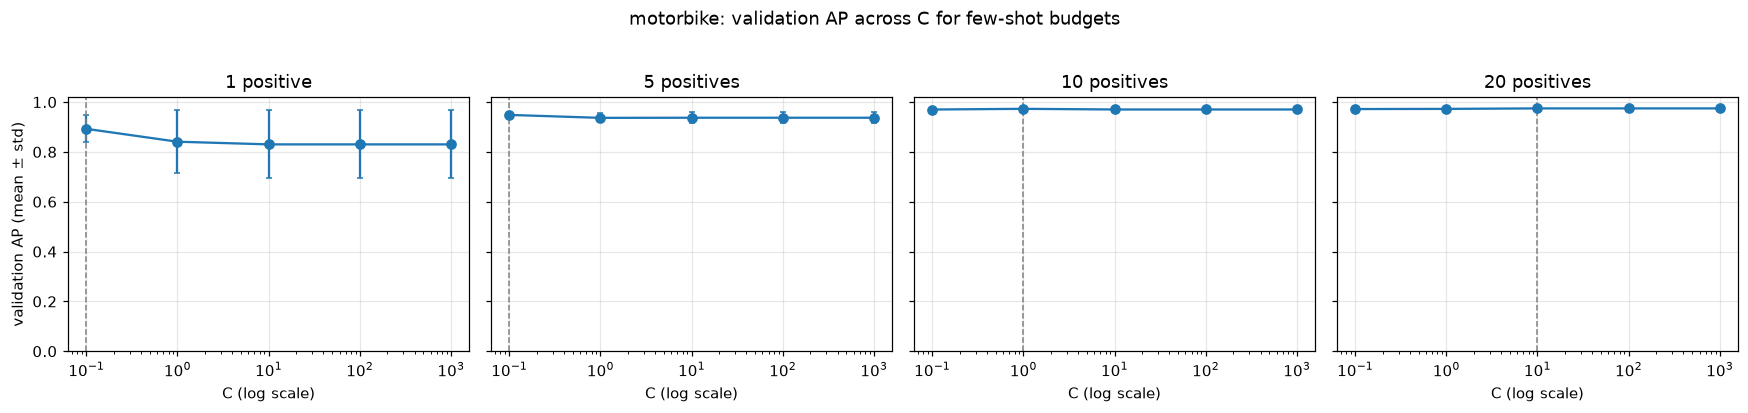

In [7]:
target = few_agg[few_agg.category == CATEGORY]
target_chosen = chosen_few[chosen_few.category == CATEGORY]

fig, axes = plt.subplots(1, len(SHOTS_FEW), figsize=(4 * len(SHOTS_FEW), 3.6), sharey=True)
axes = np.atleast_1d(axes)
for ax, shot in zip(axes, SHOTS_FEW):
    g = target[target.shot == str(shot)].sort_values("C")
    ax.errorbar(g.C, g.val_ap_mean, yerr=g.val_ap_std, marker="o", capsize=2)
    c = float(target_chosen.loc[target_chosen.shot == str(shot), "C"].iloc[0])
    ax.axvline(c, color="grey", ls="--", lw=1)
    ax.set_xscale("log")
    ax.set_title(f"{shot} positive{'s' if shot > 1 else ''}")
    ax.set_xlabel("C (log scale)")
    ax.grid(alpha=0.3)
    ax.set_ylim(0, 1.02)
axes[0].set_ylabel("validation AP (mean ± std)")
fig.suptitle(f"{CATEGORY}: validation AP across C for few-shot budgets", y=1.03)
plt.tight_layout()
plt.show()

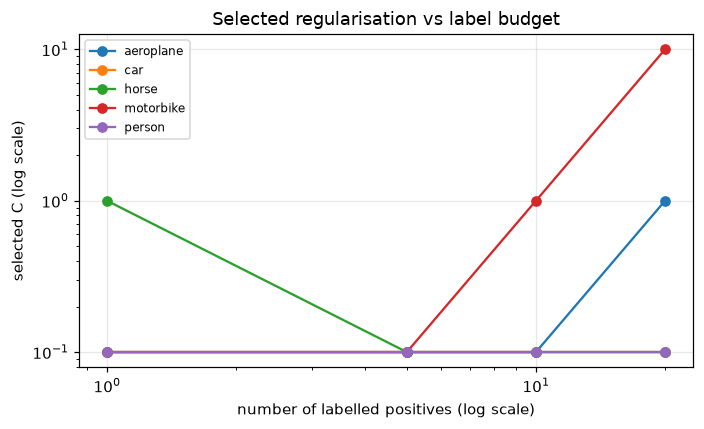

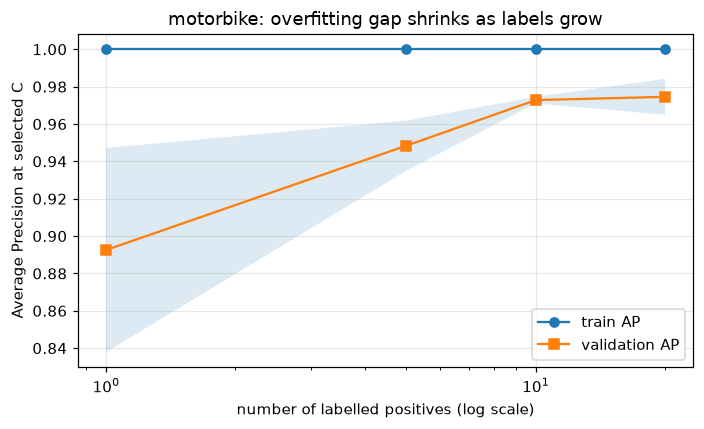

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4))
for cat in CATEGORIES:
    g = chosen_few[chosen_few.category == cat].sort_values("n_pos")
    ax.plot(g.n_pos, g.C, marker="o", label=cat)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("number of labelled positives (log scale)")
ax.set_ylabel("selected C (log scale)")
ax.set_title("Selected regularisation vs label budget")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4))
g = few_summary[few_summary.category == CATEGORY].sort_values("n_pos")
ax.plot(g.n_pos, g.train_ap_mean, marker="o", label="train AP")
ax.plot(g.n_pos, g.val_ap_mean, marker="s", label="validation AP")
ax.fill_between(g.n_pos, g.val_ap_mean - g.val_ap_std, g.val_ap_mean + g.val_ap_std,
                alpha=0.15)
ax.set_xscale("log")
ax.set_xlabel("number of labelled positives (log scale)")
ax.set_ylabel("Average Precision at selected C")
ax.set_title(f"{CATEGORY}: overfitting gap shrinks as labels grow")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()